# Baselines: text-only subreddits

Harness for `textonly_baselines.py`. The module holds the data loading, features, models, and plots;
this notebook sets the configuration, runs them, and shows the results.

**Goal:** establish the floor that larger models (gradient boosting, text embeddings) must beat, and measure
what each feature group adds, especially **timing**, the proposal's main question.

| # | Model | Uses |
|---|---|---|
| 0 | Constant (training base rate) | nothing |
| 1 | Subreddit × weekday × hour rate | subreddit, local time |
| 2 | Naive Bayes | text |
| 3 | Logistic regression | metadata (subreddit, timing, structure, history) |
| 4 | Logistic regression | text |
| 5 | Logistic regression | metadata + text |
| 6 | MLP, one hidden layer | metadata + text |

## Design

- **Data:** all text posts from the seven subreddits (`textonly_data.py`), NSFW and deleted posts removed.
- **Label:** success = engagement above the 90th percentile of the post's **subreddit and quarter**.
  `engagement = ln(1 + score) + ln(1 + comments)`.
- **Split by time:** train before `train_end`, validate from `train_end` to `val_end`, test after.
  Defaults: train ≤ 2023, validation 2024, test 2025-01 to 2026-02.
- **Sample:** at most `max_train_per_sub` training posts and `max_eval_per_sub` validation/test posts per
  subreddit, so AskReddit does not dominate. Pooled metrics weight the subreddits about equally (small
  subreddits contribute fewer posts); per-subreddit metrics are also reported.
- **Features (only information known at posting time):**
  - `subreddit`: one-hot.
  - `timing`: local hour, weekday, and month (one-hot); posts in the subreddit in the previous hour and day
    (competition); smoothed training success rates per subreddit × hour and subreddit × weekday × hour.
  - `structure`: title length and words, body length, flags (question, number, all caps, URL, flair).
  - `history`: the author's earlier posts in the subreddit, and whether the title is a repost.
  - `text`: TF-IDF of the title and the body **before the first EDIT marker** (edits added after posting leak
    the outcome; see `textonly_eda.ipynb`, section 11).
- **Metrics:** main metric PR-AUC (a random model scores the base rate, about 0.10). Also ROC-AUC and log
  loss. Per subreddit, **lift** = PR-AUC / base rate. Choose models on validation; look at test at the end.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd

import textonly_baselines as tb
import textonly_data as td

td.set_style()
pd.set_option("display.float_format", "{:,.4f}".format)

## 1. Configuration and data

In [2]:
cfg = tb.Config(
    source="local",
    label_metric="engagement",
    success_quantile=0.9,
    period="quarter",
    train_end="2024-01-01",
    val_end="2025-01-01",
    max_train_per_sub=150_000,
    max_eval_per_sub=30_000,
)
cfg

Config(source='local', label_metric='engagement', success_quantile=0.9, period='quarter', min_period_posts=100, self_only=True, train_end='2024-01-01', val_end='2025-01-01', max_train_per_sub=150000, max_eval_per_sub=30000, body_chars=1000, tfidf_max_features=50000, tfidf_min_df=5, smoothing=20, seed=42)

In [3]:
data = tb.load_data(cfg)
tb.summary(data)

posts  success_rate               first  \
split subreddit                                                         
train AskReddit              150000        0.0993 2008-04-15 21:16:07   
      Showerthoughts         150000        0.0987 2013-02-08 22:47:27   
      TwoSentenceHorror      150000        0.1001 2015-04-02 19:16:11   
      dadjokes               150000        0.1003 2013-07-01 23:09:14   
      hypotheticalsituation   14038        0.1007 2014-07-03 11:17:37   
      sysadmin               150000        0.1010 2010-10-01 20:54:34   
      unpopularopinion       150000        0.1002 2014-01-09 19:32:36   
val   AskReddit               30000        0.0981 2024-01-01 00:14:29   
      Showerthoughts          30000        0.0990 2024-01-01 00:12:59   
      TwoSentenceHorror       30000        0.1008 2024-01-01 00:03:09   
      dadjokes                29760        0.1001 2024-01-01 00:04:55   
      hypotheticalsituation   27373        0.1001 2024-01-01 01:16:24   
      sysadmin                30000        0.0994 2024-01-01 00:22:31   
      unpopularopinion        30000        0.1006 2024-01-01 00:13:16   
test  AskReddit               30000        0.1005 2025-01-01 00:13:09   
      Showerthoughts          12012        0.1001 2025-01-01 00:00:03   
      TwoSentenceHorror       30000        0.0976 2025-01-01 00:25:06   
      dadjokes                30000        0.0993 2025-01-01 00:05:50   
      hypotheticalsituation   26935        0.1001 2025-01-01 00:20:07   
      sysadmin                30000        0.1004 2025-01-01 00:27:17   
      unpopularopinion        30000        0.0994 2025-01-01 00:04:59   

                                           last  
split subreddit                                  
train AskReddit             2023-12-31 23:12:13  
      Showerthoughts        2023-12-31 20:30:51  
      TwoSentenceHorror     2023-12-31 23:52:43  
      dadjokes              2023-12-31 23:53:39  
      hypotheticalsituation 2023-12-31 23:07:50  
      sysadmin              2023-12-31 21:14:59  
      unpopularopinion      2023-12-31 23:13:33  
val   AskReddit             2024-12-31 23:58:59  
      Showerthoughts        2024-12-31 22:43:02  
      TwoSentenceHorror     2024-12-31 23:40:56  
      dadjokes              2024-12-31 23:13:10  
      hypotheticalsituation 2024-12-31 23:39:29  
      sysadmin              2024-12-31 22:49:33  
      unpopularopinion      2024-12-31 23:55:09  
test  AskReddit             2026-02-28 23:57:45  
      Showerthoughts        2026-02-28 23:11:50  
      TwoSentenceHorror     2026-02-28 23:36:06  
      dadjokes              2026-02-28 23:55:02  
      hypotheticalsituation 2026-02-28 23:37:50  
      sysadmin              2026-02-28 23:54:24  
      unpopularopinion      2026-02-28 23:21:36

## 2. Features

In [4]:
feats = tb.build_features(data)

TF-IDF: 50,000 terms in 67s
{'subreddit': 6, 'timing': 44, 'structure': 9, 'history': 2, 'text': 50000}


## 3. Baseline ladder

In [5]:
res = tb.Results(data)
models = tb.run_ladder(data, feats, res, mlp=True, mlp_units=64, mlp_max_epochs=8, mlp_patience=2)
res.table()

epoch 1: train loss 0.3177, val PR-AUC 0.1834 (8s)


epoch 2: train loss 0.2941, val PR-AUC 0.1913 (17s)


epoch 3: train loss 0.2854, val PR-AUC 0.1906 (25s)


epoch 4: train loss 0.2757, val PR-AUC 0.1894 (34s)


,val_pr_auc,val_roc_auc,val_log_loss,test_pr_auc,test_roc_auc,test_log_loss,fit_seconds
0 constant,0.0997,0.5000,0.3245,0.0996,0.5000,0.3242,NaN
1 subreddit x weekday x hour rate,0.1132,0.5374,0.3247,0.1076,0.5203,0.3262,NaN
2 naive bayes (text),0.1485,0.6199,0.3173,0.1535,0.6281,0.3158,0.1366
3 logreg (metadata),0.1243,0.5685,0.3235,0.1245,0.5650,0.3250,0.9832
4 logreg (text),0.1660,0.6415,0.3140,0.1789,0.6584,0.3102,7.0163
5 logreg (metadata + text),0.1859,0.6683,0.3090,0.1931,0.6783,0.3080,48.0175
"6 mlp, 1 hidden layer (metadata + text)",0.1913,0.6713,0.3081,0.1981,0.6796,0.3073,33.5656


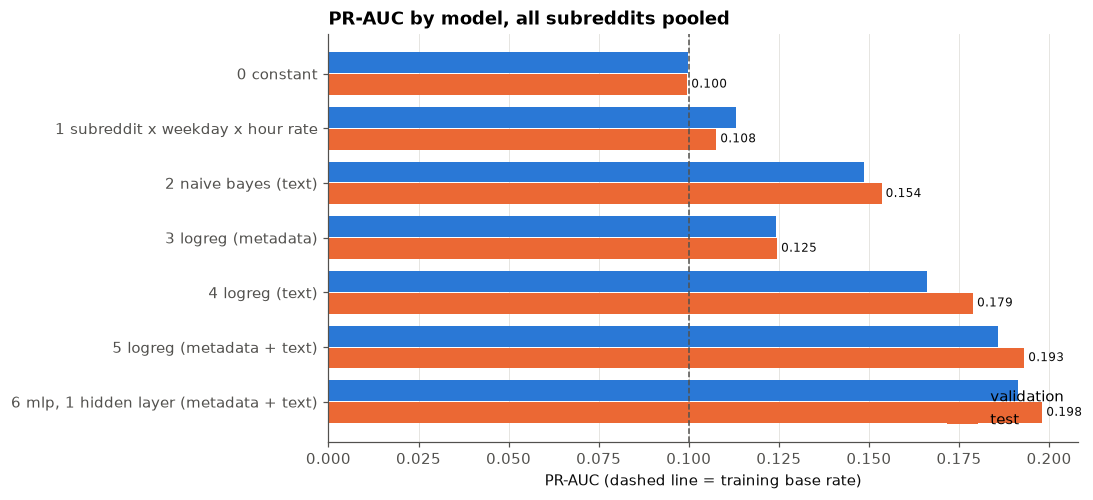

In [6]:
tb.plot_pr_auc(res);

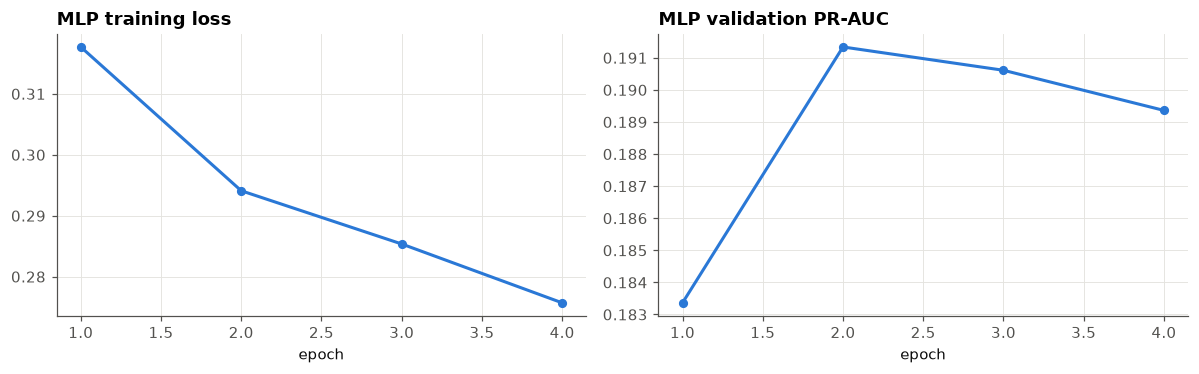

In [7]:
h = models["mlp_history"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(h.epoch, h.train_loss, color=td.BLUE, marker="o", markersize=5); axes[0].set_title("MLP training loss")
axes[1].plot(h.epoch, h.val_pr_auc, color=td.BLUE, marker="o", markersize=5); axes[1].set_title("MLP validation PR-AUC")
for ax in axes:
    ax.set_xlabel("epoch")
plt.tight_layout()

### By subreddit

Lift = PR-AUC / base rate (1 = no better than random). Pooled numbers can hide that a model works well in
one subreddit and not at all in another.

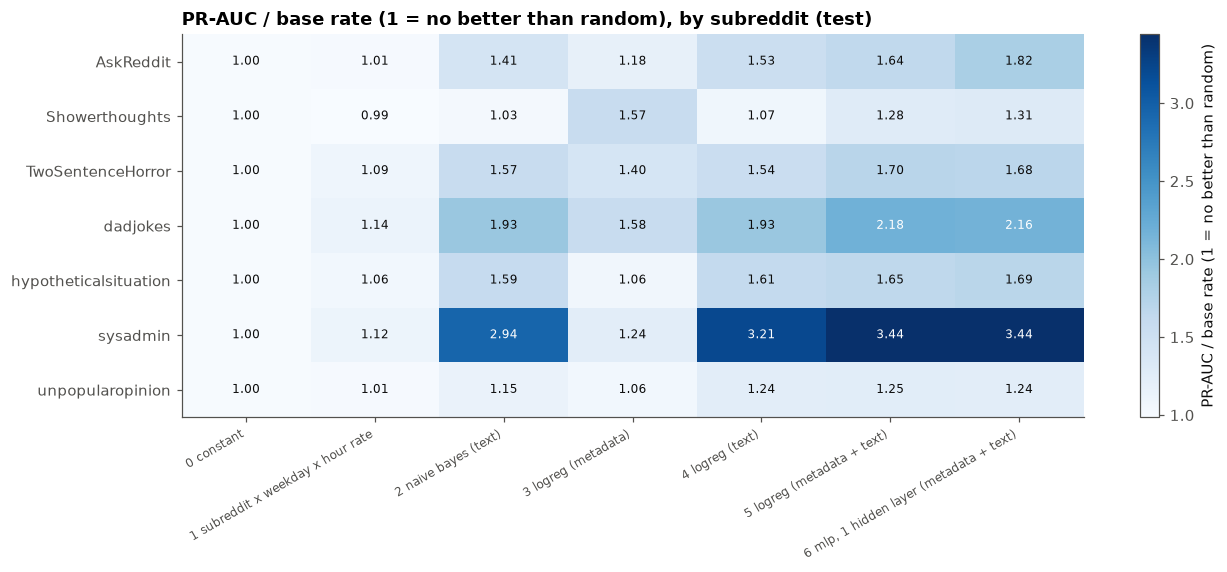

In [8]:
tb.plot_per_subreddit(res, "test", "lift");

In [9]:
res.per_subreddit("test", "pr_auc")

model,0 constant,1 subreddit x weekday x hour rate,2 naive bayes (text),3 logreg (metadata),4 logreg (text),5 logreg (metadata + text),"6 mlp, 1 hidden layer (metadata + text)"
subreddit,,,,,,,
AskReddit,0.1005,0.1019,0.1417,0.1189,0.1535,0.1645,0.1829
Showerthoughts,0.1001,0.0988,0.1028,0.1569,0.1077,0.1282,0.1308
TwoSentenceHorror,0.0976,0.1069,0.1528,0.1371,0.1508,0.1661,0.1644
dadjokes,0.0993,0.1132,0.1921,0.1568,0.1920,0.2168,0.2146
hypotheticalsituation,0.1001,0.1058,0.1592,0.1064,0.1613,0.1655,0.1690
sysadmin,0.1004,0.1120,0.2951,0.1249,0.3223,0.3455,0.3451
unpopularopinion,0.0994,0.1008,0.1143,0.1055,0.1231,0.1243,0.1231


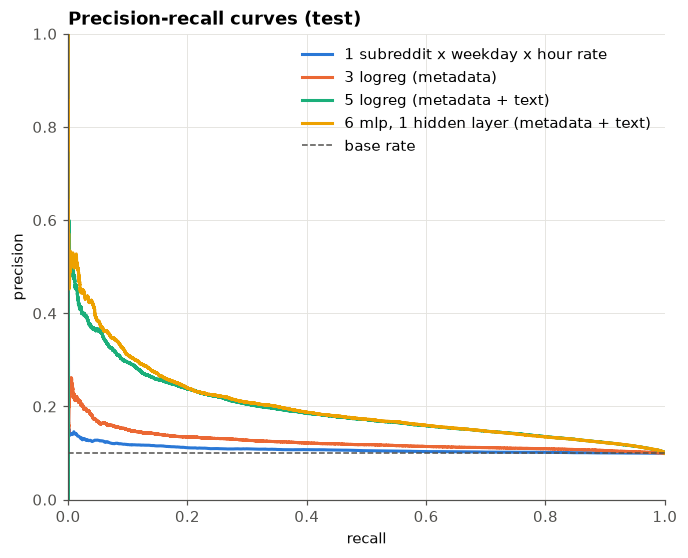

In [10]:
tb.plot_pr_curves(res, ["1 subreddit x weekday x hour rate", "3 logreg (metadata)", "5 logreg (metadata + text)",
                        "6 mlp, 1 hidden layer (metadata + text)"]);

### What the linear models learned

Metadata features are standardized, so coefficient sizes are comparable. One-hot groups drop their first
category (hour 0, Monday, January, the first subreddit alphabetically), so those coefficients are relative to it.

In [11]:
tb.coefficients(models["lr_meta"], feats, tb.META, top=15)

,coefficient
subreddit_hypotheticalsituation,-0.4973
subreddit_sysadmin,-0.3301
subreddit_TwoSentenceHorror,-0.3177
subreddit_Showerthoughts,-0.2220
log_posts_prev_hour,-0.2128
has_body,-0.2120
subreddit_dadjokes,-0.2081
subreddit_unpopularopinion,-0.1499
local_hour_7,-0.1409
local_hour_6,-0.1405


In [12]:
tb.top_terms(models["lr_text"], feats, n=25)

,most negative,most positive
0,hi,sysadmins
1,is there,sysadmin
2,error,rant
3,there way,psa
4,hello,your username
5,any ideas,server room
6,how can,ransomware
7,has anyone,hr
8,sync,on call
9,suggestions,https


## 4. Ablation: what each feature group adds

Logistic regression on growing feature sets. The key comparison for the proposal is
**content** vs. **content + timing**: the gain is what timing adds once the text and structure of the
post are known.

In [13]:
ablation, ablation_res = tb.run_ablation(data, feats)
ablation

,val_pr_auc,val_roc_auc,val_log_loss,test_pr_auc,test_roc_auc,test_log_loss,fit_seconds
subreddit only,0.0999,0.5012,0.3245,0.0997,0.4997,0.3242,0.1715
+ timing,0.1145,0.5428,0.3245,0.1087,0.5253,0.3260,0.3715
+ structure,0.1087,0.5356,0.3242,0.1160,0.5558,0.3227,0.5171
+ history,0.1179,0.5538,0.3232,0.1182,0.5571,0.3228,0.2791
+ text,0.1805,0.6524,0.3112,0.1958,0.6679,0.3075,15.0975
content (structure + history + text),0.1861,0.6614,0.3095,0.2018,0.6820,0.3049,38.3311
content + timing (all),0.1835,0.6663,0.3095,0.1908,0.6775,0.3084,45.0204


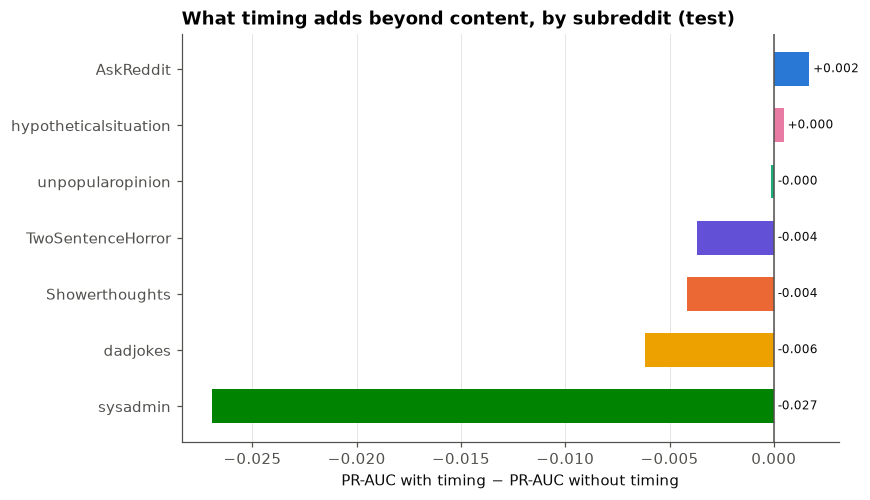

In [14]:
tb.plot_timing_gain(ablation_res, "test");

In [15]:
ablation_res.per_subreddit("test", "pr_auc")

model,subreddit only,+ timing,+ structure,+ history,+ text,content (structure + history + text),content + timing (all)
subreddit,,,,,,,
AskReddit,0.1005,0.1036,0.0757,0.1516,0.1609,0.1630,0.1646
Showerthoughts,0.1001,0.0959,0.1265,0.1572,0.1077,0.1326,0.1284
TwoSentenceHorror,0.0976,0.1097,0.1465,0.1248,0.1559,0.1672,0.1635
dadjokes,0.0993,0.1160,0.1659,0.1226,0.1934,0.2193,0.2132
hypotheticalsituation,0.1001,0.1080,0.1070,0.0847,0.1652,0.1668,0.1673
sysadmin,0.1004,0.1132,0.1287,0.1095,0.3678,0.3681,0.3411
unpopularopinion,0.0994,0.1025,0.1043,0.1061,0.1234,0.1255,0.1254


## Next steps

- **Larger models:** gradient boosting on the tabular groups (`HistGradientBoostingClassifier`, or LightGBM
  after `brew install libomp`), which can learn subreddit-specific timing patterns without the lookup rates.
- **Text embeddings:** add an `embeddings` group (for example `all-MiniLM-L6-v2` on title + clean body) and
  compare it with `text` (TF-IDF) in the ablation. If embeddings do not beat TF-IDF, they are not needed.
- **Tuning on validation only:** `C`, TF-IDF size, MLP units and regularization. Report test once.
- **Threshold metrics** (precision, recall, F1) at a threshold chosen on validation, as the proposal asks.